In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

De un proyecto sólo se conserva la matriz de Zaderenko sin calcular: en la casilla (i, j) figura la actividad que va del nodo i al nodo j y, entre paréntesis, su duración en días; las ficticias aparecen como tales. Los nodos están numerados de modo que todo arco va de un número menor a uno mayor.

In [3]:
#| tbl-cap: "Matriz de Zaderenko del enunciado"
#| label: tbl-matrizEnunciado
matriz_enunciado = pd.DataFrame('', index=['1', '2', '3', '4', '5', '6', '7', '8'], columns=['1', '2', '3', '4', '5', '6', '7', '8'])
matriz_enunciado.loc['1', '2'] = 'B (5)'
matriz_enunciado.loc['1', '3'] = 'A (5)'
matriz_enunciado.loc['2', '4'] = 'ficticia'
matriz_enunciado.loc['2', '5'] = 'D (6)'
matriz_enunciado.loc['3', '4'] = 'ficticia'
matriz_enunciado.loc['3', '7'] = 'E (3)'
matriz_enunciado.loc['4', '5'] = 'C (6)'
matriz_enunciado.loc['5', '6'] = 'F (2)'
matriz_enunciado.loc['6', '7'] = 'ficticia'
matriz_enunciado.loc['6', '8'] = 'H (8)'
matriz_enunciado.loc['7', '8'] = 'G (5)'
matriz_enunciado.index.name = 'nodo'
matriz_enunciado

,1,2,3,4,5,6,7,8
nodo,,,,,,,,
1,,B (5),A (5),,,,,
2,,,,ficticia,D (6),,,
3,,,,ficticia,,,E (3),
4,,,,,C (6),,,
5,,,,,,F (2),,
6,,,,,,,ficticia,H (8)
7,,,,,,,,G (5)
8,,,,,,,,


In [4]:
pregunta_1 = "1. Reconstruya el cuadro de prelaciones inmediatas del proyecto (las ficticias transmiten prelaciones pero no son actividades).  "
pregunta_2 = "2. Dibuje el grafo PERT y compruebe que reproduce la matriz.  "
pregunta_3 = "3. Calcule los tiempos más tempranos y más tardíos de los nodos y la duración del proyecto.  "
pregunta_4 = "4. Obtenga el calendario de las actividades y el camino crítico.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Reconstruya el cuadro de prelaciones inmediatas del proyecto (las ficticias transmiten prelaciones pero no son actividades).  

2. Dibuje el grafo PERT y compruebe que reproduce la matriz.  

3. Calcule los tiempos más tempranos y más tardíos de los nodos y la duración del proyecto.  

4. Obtenga el calendario de las actividades y el camino crítico.  

# Resolución

## Apartado 1

In [5]:
display(Markdown(pregunta_1))

1. Reconstruya el cuadro de prelaciones inmediatas del proyecto (las ficticias transmiten prelaciones pero no son actividades).  

Cada casilla no vacía es un arco (i → j). Las predecesoras de una actividad que sale del nodo i son las actividades que entran en i, más las que entran en los nodos desde los que llega una ficticia a i (siguiendo las cadenas de ficticias hacia atrás).

In [6]:
arcos = {}
for i in matriz_enunciado.index:
    for j in matriz_enunciado.columns:
        txt = matriz_enunciado.loc[i, j]
        if txt:
            arcos[(i, j)] = ('ficticia' if txt == 'ficticia' else txt.split(' ')[0], 0 if txt == 'ficticia' else int(txt.split('(')[1].rstrip(')')))
def entran(nodo):
    acts = set()
    for (i, j), (nombre, _) in arcos.items():
        if j == nodo:
            acts |= {nombre} if nombre != 'ficticia' else entran(i)
    return acts
prelaciones_dict, duraciones = {}, {}
for (i, j), (nombre, d) in arcos.items():
    if nombre != 'ficticia':
        prelaciones_dict[nombre] = ','.join(sorted(entran(i))) or '---'
        duraciones[nombre] = d
datos_proyecto = pd.DataFrame({'predecessor': pd.Series(prelaciones_dict), 'duration': pd.Series(duraciones)}).sort_index()
datos_proyecto.index.name = 'activity'
datos_proyecto

,predecessor,duration
activity,,
A,---,5
B,---,5
C,"A,B",6
D,B,6
E,A,3
F,"C,D",2
G,"E,F",5
H,F,8


## Apartado 2

In [7]:
display(Markdown(pregunta_2))

2. Dibuje el grafo PERT y compruebe que reproduce la matriz.  

In [8]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

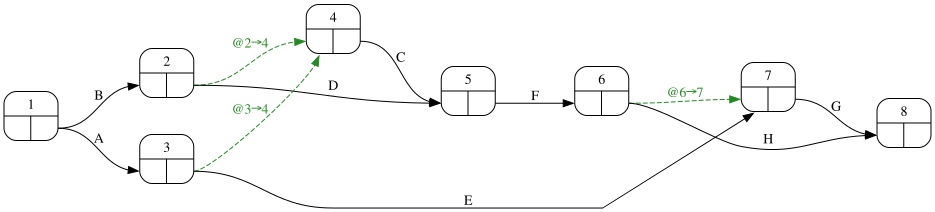

In [9]:
#| fig-cap: "Grafo PERT reconstruido"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)

La numeración de los nodos puede diferir de la del enunciado (hay varias numeraciones válidas), pero la matriz tiene las mismas actividades en las mismas posiciones relativas.

## Apartado 3

In [10]:
display(Markdown(pregunta_3))

3. Calcule los tiempos más tempranos y más tardíos de los nodos y la duración del proyecto.  

In [11]:
#| tbl-cap: "Matriz de Zaderenko calculada"
#| label: tbl-zaderenko
proyecto.zaderenko(durations=datos_proyecto['duration'])

,1,2,3,4,5,6,7,8,early
1,,5.0,5.0,,,,,,0.0
2,,,,0.0,6.0,,,,5.0
3,,,,0.0,,,3.0,,5.0
4,,,,,6.0,,,,5.0
5,,,,,,2.0,,,11.0
6,,,,,,,0.0,8.0,13.0
7,,,,,,,,5.0,13.0
8,,,,,,,,,21.0
late,0.0,5.0,5.0,5.0,11.0,13.0,16.0,21.0,


In [12]:
resultados_pert = proyecto.calculate_pert(durations=datos_proyecto['duration'])
display(resultados_pert['nodes'].T)
Markdown(f'La duración del proyecto es {proyecto.duration(datos_proyecto["duration"])} días.')

,1,2,3,4,5,6,7,8
early,0,5,5,5,11,13,13,21
late,0,5,5,5,11,13,16,21


La duración del proyecto es 21 días.

## Apartado 4

In [13]:
display(Markdown(pregunta_4))

4. Obtenga el calendario de las actividades y el camino crítico.  

In [14]:
#| tbl-cap: "Calendario del proyecto"
#| label: tbl-calendario
proyecto.calendar(datos_proyecto['duration'])[['inicio_mas_temprano', 'fin_mas_temprano', 'inicio_mas_tardio', 'fin_mas_tardio', 'H_total']]

,inicio_mas_temprano,fin_mas_temprano,inicio_mas_tardio,fin_mas_tardio,H_total
activity,,,,,
A,0,5,0,5,0
B,0,5,0,5,0
C,5,11,5,11,0
D,5,11,5,11,0
E,5,8,13,16,8
F,11,13,11,13,0
G,13,18,16,21,3
H,13,21,13,21,0


In [15]:
camino_critico = proyecto.display_critical_path(datos_proyecto['duration'])

- Route_2 :	A, C, F, H <br> 

- Route_5 :	B, C, F, H <br> 

- Route_7 :	B, D, F, H <br> 